In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

Setup: 

Using simulated neuromarketing data (pupil dilation, gaze duration, heart
rate, and frontal lobe activation predicting product likeness), I wanted to test what happens
when gaze duration is omitted from a regression model, at varying levels of correlation
between gaze duration and pupil dilation (0.1 to 0.9).

In [ ]:
# GOAL: figure out which biometric signal (pupil dilation, gaze duration, heart rate,
# or frontal lobe activation) is the strongest TRUE predictor of product likeness /
# purchase intent, and show how a flawed model (missing gaze duration) can give a
# WRONG answer to that question when pupil dilation and gaze duration are strongly
# correlated with each other.

In [7]:
true_intercept = 20       # baseline likeness score with everything at zero
true_b_dilation = 2.0        # true effect of pupil dilation on likeness
true_b_gaze = 1.5            # true effect of gaze duration on likeness 
true_b_heart = 0.5           # true effect of heart rate on likeness (our true weakest effect)
true_b_frontal = 4.0         # true effect of frontal lobe activation on likeness(our true strongest effect)

noise_sd = 5  #how much random noise we add
#This are the true effects that we are choosing, in our fake simulated data. With an underlying truth, where pupil
# dilation and gaze duration are correlated to each other, and frontal lobe activation and heart rate are indipendent.

In [ ]:
#How correlated pupil dilation and gaze duration are, at different levels we want to test.
# 0 = no relationship at all, 1 = basically identical.

correlation_levels = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

n_participants = 200
n_resamples = 500

# This is Monte Carlo simulation, NOT bootstrap resampling.
# Each of the 500 iterations generates a completely NEW, independent sample of
# 200 fake people from the true model, brand new random X values and new noise
# every time, rather than reshuffling/resampling rows from one fixed dataset.

In [ ]:
def generate_data(correlation, n=n_participants):
    # Generate correlated pupil dilation and gaze duration correlation, using a multivariate normal distribution

    mean = [0, 0] #This is thestarting point for both raw variables before we shift them into realistic units.
    cov_matrix = [[1, correlation],
                  [correlation, 1]] #this is where we literally tell the simulation how correlated the two variables should be

    dilation_raw, gaze_raw = np.random.multivariate_normal(mean, cov_matrix, n).T #This generates n correlated pairs of raw numbers, then splits them into two separate lists

    # rescale to more realistic ranges
    pupil_dilation = dilation_raw * 1.5 + 5       # centered around 5mm
    gaze_duration = gaze_raw * 300 + 1200         # centered around 1200ms
    heart_rate = np.random.normal(75, 8, n)              # centered around 75 bpm
    frontal_lobe_activation = np.random.normal(50, 10, n) # centered around 50 (since standard neuro measures don't reduce to a single clean unit we just use a scale 0-100)

    # Now we generate the outcome variable (product likeness / purchase intent) based on the true model, with some added noise.
    noise = np.random.normal(0, noise_sd, n)

    likeness = (true_intercept
                + true_b_dilation * pupil_dilation
                + true_b_gaze * gaze_duration / 100    # scaled down so its effect is correctly comparable to the other predictors (THIS SCALE IS ONLY IN THIS FORMULA)
                + true_b_heart * heart_rate
                + true_b_frontal * frontal_lobe_activation
                + noise)

    likeness = likeness / 3 # scale down to a more realistic range (0-100)
    data = pd.DataFrame({
        'pupil_dilation': pupil_dilation,
        'gaze_duration': gaze_duration,
        'heart_rate': heart_rate,
        'frontal_lobe_activation': frontal_lobe_activation,
        'likeness': likeness
    })

    return data

In [22]:
#Let's test the function to make sure it works, generating 1 sample with high correlation at 0.9

test_data = generate_data(correlation=0.9, n=200)

print(test_data.head())  # shows the first 5 rows
print()
print("Actual correlation between pupil_dilation and gaze_duration:",
      test_data['pupil_dilation'].corr(test_data['gaze_duration']))

   pupil_dilation  gaze_duration  heart_rate  frontal_lobe_activation  \
0        1.364556     280.524172   69.849605                49.160287   
1        2.658666     834.600283   73.010531                53.716917   
2        4.551218     963.344451   85.311468                33.492920   
3        7.792523    1659.477383   84.402840                56.767267   
4        6.069252    1485.326871   81.423545                54.267079   

     likeness  
0   86.008921  
1   99.984185  
2   75.028855  
3  110.924187  
4  105.074934  

Actual correlation between pupil_dilation and gaze_duration: 0.9011135155372284


In [23]:
def fit_models(data):
    #Fits two OLS regressions on the same dataset:
     #full: includes gaze_duration
     #restricted: omits gaze_duration
     #Returns both fitted results.

 X_full = sm.add_constant(data[['pupil_dilation', 'gaze_duration', 'heart_rate', 'frontal_lobe_activation']])

 X_restricted = sm.add_constant(data[['pupil_dilation', 'heart_rate', 'frontal_lobe_activation']])

 y = data['likeness']

 full_model = sm.OLS(y, X_full).fit()
 restricted_model = sm.OLS(y, X_restricted).fit()

 return full_model, restricted_model

In [24]:
#Let's test the fitted models

full_model, restricted_model = fit_models(test_data)

print("FULL MODEL (includes gaze_duration):")
print(full_model.params)
print()
print("RESTRICTED MODEL (omits gaze_duration):")
print(restricted_model.params)

FULL MODEL (includes gaze_duration):
const                      6.469633
pupil_dilation             0.676822
gaze_duration              0.004706
heart_rate                 0.168005
frontal_lobe_activation    1.339264
dtype: float64

RESTRICTED MODEL (omits gaze_duration):
const                      8.120813
pupil_dilation             1.528618
heart_rate                 0.165304
frontal_lobe_activation    1.338169
dtype: float64


In [ ]:
#As we can see, the full model it's unibiased, withfrontal lobe activation as the strongest predictor, 
#while the restricted model incorrectly identifies pupil dilation as the strongest predictor due to the omitted variable bias caused by the correlation between pupil dilation and gaze duration.
#Now my question is, how does the strength of the correlation between pupil dilation and gaze duration affect the magnitude of this bias?
#Let's run a simulation.

In [38]:
true_dilation_value = true_b_dilation / 3   # remember we divided likeness by 3 earlier

results = []  # we'll store one row of results per (correlation, resample)

for correlation in correlation_levels:
    for i in range(n_resamples):
        sample = generate_data(correlation) #generate a fresh, brand-new fake sample at this correlation level and fit the two models on it
        full_model, restricted_model = fit_models(sample)

        #the coefficient we care about from each model
        dilation_full = full_model.params['pupil_dilation']
        dilation_restricted = restricted_model.params['pupil_dilation']
        frontal_restricted = restricted_model.params['frontal_lobe_activation']

        #check if the restricted model got the ranking WRONG
        # (wrong = pupil dilation appears bigger than frontal lobe activation)
        ranking_wrong = dilation_restricted > frontal_restricted

        # get the 95% confidence interval for pupil_dilation in the restricted model ---
        ci = restricted_model.conf_int(alpha=0.05)  # returns lower/upper bounds for every predictor
        ci_lower = ci.loc['pupil_dilation', 0]
        ci_upper = ci.loc['pupil_dilation', 1]

        # does the CI actually contain the true value?
        ci_contains_true = ci_lower <= true_dilation_value <= ci_upper

        results.append({
            'correlation': correlation,
            'dilation_full': dilation_full,
            'dilation_restricted': dilation_restricted,
            'frontal_restricted': frontal_restricted,
            'ranking_wrong': ranking_wrong,
            'ci_lower': ci_lower,
            'ci_upper': ci_upper,
            'ci_contains_true': ci_contains_true
        })

# Turn the list of results into one big table
results_df = pd.DataFrame(results)
print(results_df.shape)   # should show (4500, 8) → 9 correlation levels × 500 resamples
print(results_df.head())

(4500, 8)
   correlation  dilation_full  dilation_restricted  frontal_restricted  \
0          0.1       0.633481             0.770142            1.306166   
1          0.1       0.584629             0.879479            1.317177   
2          0.1       0.664144             0.771426            1.328390   
3          0.1       0.630111             0.725841            1.357826   
4          0.1       0.718810             0.960702            1.310405   

   ranking_wrong  ci_lower  ci_upper  ci_contains_true  
0          False  0.568052  0.972233              True  
1          False  0.665296  1.093663              True  
2          False  0.582966  0.959885              True  
3          False  0.498202  0.953481              True  
4          False  0.771335  1.150070             False  


In [ ]:
#ranking_wrong asks: "does pupil dilation's estimate happen to be bigger than frontal lobe activation's estimate?"

#ci_contains_true asks: "does pupil dilation's confidence interval actually contain the true pupil dilation value (0.667)?"

In [34]:
summary = results_df.groupby('correlation').agg(
    avg_dilation_full=('dilation_full', 'mean'),
    avg_dilation_restricted=('dilation_restricted', 'mean'),
    pct_ranking_wrong=('ranking_wrong', 'mean'),
    pct_ci_contains_true=('ci_contains_true', 'mean')
)

summary['pct_ranking_wrong'] = summary['pct_ranking_wrong'] * 100
summary['pct_ci_contains_true'] = summary['pct_ci_contains_true'] * 100

print(summary)

             avg_dilation_full  avg_dilation_restricted  pct_ranking_wrong  \
correlation                                                                  
0.1                   0.663017                 0.771410                0.0   
0.2                   0.668236                 0.863677                0.0   
0.3                   0.662095                 0.961139                0.0   
0.4                   0.667904                 1.065755                0.6   
0.5                   0.666479                 1.169507                4.8   
0.6                   0.665407                 1.265038               25.4   
0.7                   0.668966                 1.369405               67.6   
0.8                   0.661568                 1.465409               93.8   
0.9                   0.668024                 1.569240               99.2   

             pct_ci_contains_true  
correlation                        
0.1                          85.4  
0.2                          53.4

In [ ]:
#From the summary table, we can see that as the correlation between pupil dilation and gaze duration increases, the average coefficient for pupil dilation in the restricted model becomes more biased (higher) compared to the full model. 
#Additionally, the percentage of times the restricted model incorrectly ranks pupil dilation as a stronger predictor than frontal lobe activation also increases with higher correlation levels. 
#This demonstrates the true impact of correlation on model bias.

#omitting a correlated variable is fine up to a point, but past roughly correlation ≈ 0.5-0.6, 
#it becomes increasingly likely to give you the wrong answer about which predictor matters most, 
#and by 0.8+ it's nearly guaranteed that it will mislead you.

#An unbiased model'CI miss the true value only about 5% of the time, 
#If we see it missing way more often than 5%, that's proof the model is broken, not just unlucky.
#We use it as a second way to confirm that the restricted model is biased, and that the bias grows with correlation strength.

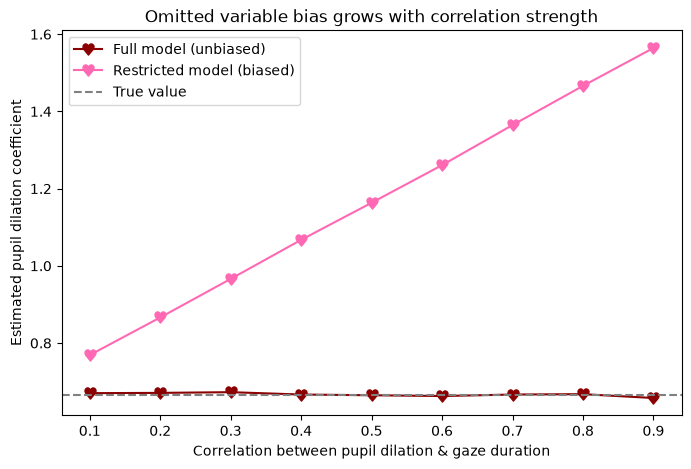

In [31]:
plt.figure(figsize=(8,5))
plt.plot(summary.index, summary['avg_dilation_full'], marker='$\u2665$', markersize=8, color='darkred', label='Full model (unbiased)')
plt.plot(summary.index, summary['avg_dilation_restricted'], marker='$\u2665$', markersize=8, color='hotpink', label='Restricted model (biased)')
plt.axhline(y=true_b_dilation/3, color='gray', linestyle='--', label='True value')
plt.xlabel('Correlation between pupil dilation & gaze duration')
plt.ylabel('Estimated pupil dilation coefficient')
plt.title('Omitted variable bias grows with correlation strength')
plt.legend()
plt.show()

In [ ]:
#Bias in the restricted model's coefficient grows with correlation strength, 
#while the full model stays consistently accurate.

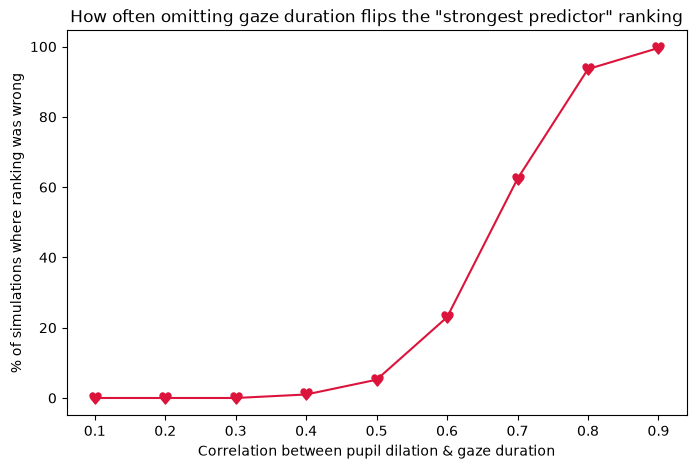

In [32]:
plt.figure(figsize=(8,5))
plt.plot(summary.index, summary['pct_ranking_wrong'], marker='$\u2665$', markersize=8, color='crimson')
plt.xlabel('Correlation between pupil dilation & gaze duration')
plt.ylabel('% of simulations where ranking was wrong')
plt.title('How often omitting gaze duration flips the "strongest predictor" ranking')
plt.show()

In [ ]:
#Past roughly correlation ≈ 0.5, omitting a correlated variable 
#becomes increasingly likely to identify the wrong predictor as "most important."

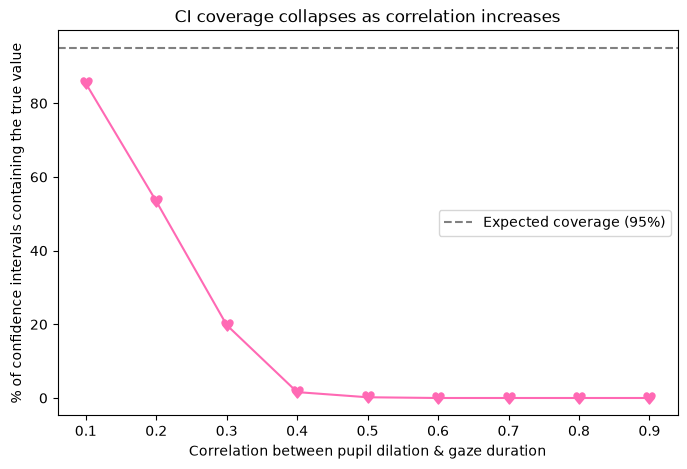

In [37]:
plt.figure(figsize=(8,5))
plt.plot(
    summary.index,
    summary['pct_ci_contains_true'],
    marker='$\u2665$',
    markersize=8,
    color='hotpink'
)
plt.axhline(y=95, color='gray', linestyle='--', label='Expected coverage (95%)')
plt.xlabel('Correlation between pupil dilation & gaze duration')
plt.ylabel('% of confidence intervals containing the true value')
plt.title('CI coverage collapses as correlation increases')
plt.legend()
plt.show()

In [ ]:
#CI coverage collapses almost immediately, 
# and much faster than the ranking flips, an earlier warning sign of bias. Also is nice to notice how this two last tables
#are mirror opposite of each other.

Summary & Interpretation

My main goal was to see if and how the severity of that inference damage depends directly on how
correlated the omitted variable is.

Finding 1 

Bias grows with correlation, and it's never truly zero.

The restricted model's pupil dilation coefficient is consistently inflated above its true value (0.667/2.0)
at every correlation level tested, even at correlation 0.1, the average estimate (0.77)
is already biased upward. As correlation increases, this bias grows roughly linearly,
reaching more than double the true value (1.57) at correlation 0.9.

Finding 2 

Past a threshold, the bias flips the "strongest predictor" conclusion.

The restricted model wrongly ranks pupil dilation above frontal lobe activation (the true
strongest predictor) increasingly often as correlation rises, going near 0% through
correlation 0.3, then climbing sharply between 0.5 and 0.8, reaching 99% and more by correlation
0.9. 
This shows omitted variable bias isn't just a matter of degree, past roughly
correlation 0.5-0.6, it becomes likely to produce an wrong conclusion about
which biometric signal actually matters most.

Finding 3

Confidence interval coverage breaks down earlier and faster than the ranking does. 

A properly behaving 95% CI should contain the true value about 95% of
the time. Instead, coverage starts collapsing almost immediately. 
Already down to 85% at correlation 0.1, and below 5% by correlation 0.4  well before the ranking itself
starts flipping (which doesn't happen in earnest until ~0.5). 

We can say then that CI coverage acts as an earlier, more sensitive warning sign of bias than the ranking: a researcher
checking "does my CI look reasonable?" would be misled long before their bigger-picture
conclusion (which predictor is strongest) goes wrong.

Why this matters for neuromarketing:

If pupil dilation and gaze duration are correlated (a plausible real-world scenario, since both are downstream signals of
engagement/arousal), a study that only measures pupil dilation could easily overstate
its importance relative to other signals like frontal lobe activation, leading a company
to invest in the wrong biometric measurement entirely. Also becayse often eye-tracking devices are cheaper than, for example, EEG machines.

